# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** **Ghulam Mustafa**
- **Student ID:** **023-24-0212**
- **Section:** **G**
- **GitHub:** **https://github.com/mustafaa101/Machine-learning**
- **Kaggle:**
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_samples, silhouette_score, adjusted_rand_score
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA

# Set the required random seed everywhere
SEED = 42
np.random.seed(SEED)

# Styling for plots
sns.set_theme(style="whitegrid")

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [3]:
# Task 0.1: Load and check the data
# Make sure 'Mall_Customers.csv' is uploaded to your Colab or workspace environment
df_mall = pd.read_csv('Mall_Customers.csv')

# Rename columns for convenience
df_mall = df_mall.rename(columns={
    'Annual Income (k$)': 'Income',
    'Spending Score (1-100)': 'Spending'
})

print("--- Data Shape ---")
print(df_mall.shape)

print("\n--- Missing Values ---")
print(df_mall.isnull().sum())

print("\n--- Duplicate Rows ---")
print(df_mall.duplicated().sum())

print("\n--- Gender Counts ---")
print(df_mall['Gender'].value_counts())

print("\n--- Descriptive Statistics ---")
print(df_mall[['Age', 'Income', 'Spending']].describe())

--- Data Shape ---
(200, 5)

--- Missing Values ---
CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64

--- Duplicate Rows ---
0

--- Gender Counts ---
Gender
Female    112
Male       88
Name: count, dtype: int64

--- Descriptive Statistics ---
              Age      Income    Spending
count  200.000000  200.000000  200.000000
mean    38.850000   60.560000   50.200000
std     13.969007   26.264721   25.823522
min     18.000000   15.000000    1.000000
25%     28.750000   41.500000   34.750000
50%     36.000000   61.500000   50.000000
75%     49.000000   78.000000   73.000000
max     70.000000  137.000000   99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


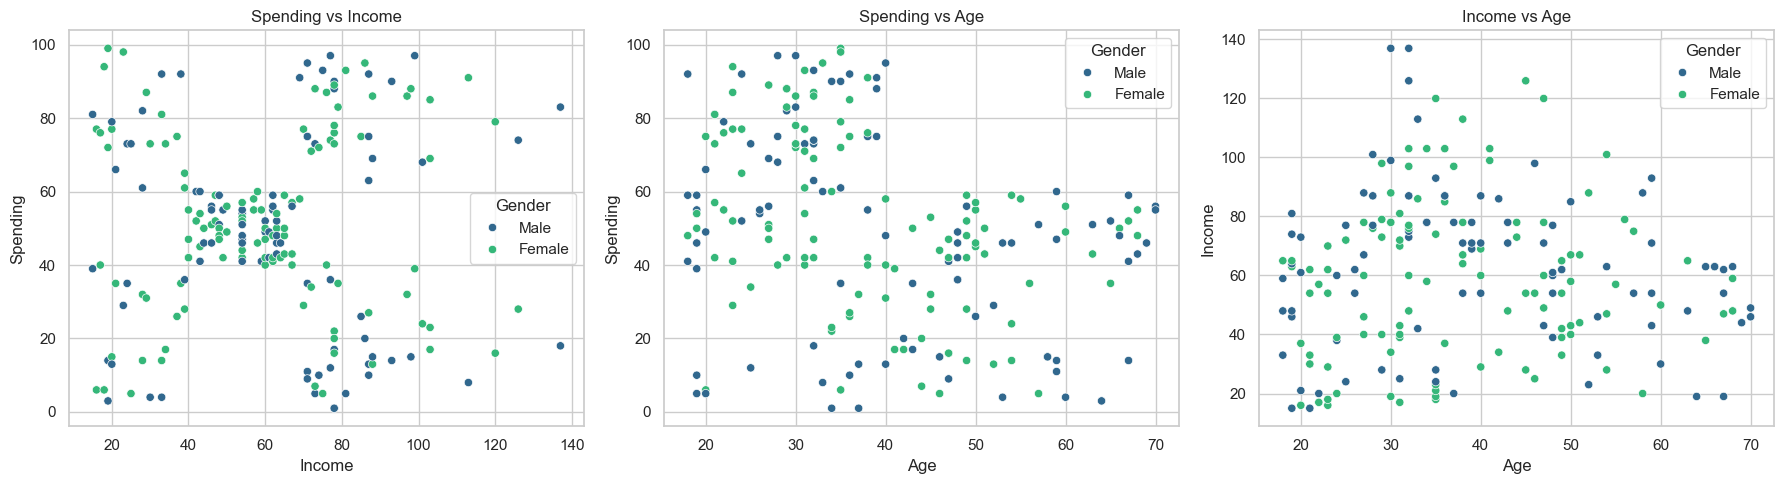

In [4]:
# Task 0.2: Look at the data before clustering (Side-by-side scatter plots)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df_mall, x='Income', y='Spending', hue='Gender', ax=axes[0], palette='viridis')
axes[0].set_title('Spending vs Income')

sns.scatterplot(data=df_mall, x='Age', y='Spending', hue='Gender', ax=axes[1], palette='viridis')
axes[1].set_title('Spending vs Age')

sns.scatterplot(data=df_mall, x='Age', y='Income', hue='Gender', ax=axes[2], palette='viridis')
axes[2].set_title('Income vs Age')

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



(a) How many groups do you see visually in each plot and which is clearest?
Spending vs. Income: Shows 5 distinct clusters (e.g., high income/high spending, high income/low spending, low income/high spending, low income/low spending, and a middle-income/middle-spending group). This is by far the clearest plot showing well-separated groupings.

Spending vs. Age: Shows roughly 3 to 4 diffuse groupings (primarily concentrated among younger ages with higher spending scores, and older age brackets with lower or moderate spending), but with considerable overlap.

Income vs. Age: Shows 2 to 3 loose, overlapping blobs with no sharp boundaries separating them.

(b) Why can we not use accuracy or a train/test split for clustering?
Clustering is an unsupervised learning technique, meaning the dataset lacks a target label column (
y).

Because there is no pre-defined "right answer" or ground truth class for each customer, it is impossible to calculate classification accuracy or perform a standard train/test evaluation. Instead, clustering performance must be judged using distance metrics, silhouette scores, and business common sense.

---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [5]:
# Task 1.1: Lecture Example 1 in code (one feature)
x1 = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
k1 = 2
centroids1 = np.array([4.0, 11.0])

for iteration in range(10):
    # Compute distances: shape (9, 2)
    distances = np.abs(x1[:, None] - centroids1[None, :])
    # Assign steps
    labels1 = distances.argmin(axis=1)
    
    print(f"Iteration {iteration+1}: Clusters -> {labels1}, Centroids -> {centroids1}")
    
    # Update step
    new_centroids = np.array([x1[labels1 == i].mean() for i in range(k1)])
    
    if np.allclose(new_centroids, centroids1):
        print(f"Converged at iteration {iteration+1}!")
        centroids1 = new_centroids
        break
    centroids1 = new_centroids

# Final Inertia (Sum of squared distances to own centroid)
inertia1 = np.sum((x1 - centroids1[labels1]) ** 2)
print(f"Final Centroids: {centroids1}, Final Inertia: {inertia1}\n")

Iteration 1: Clusters -> [0 0 1 1 0 1 1 1 1], Centroids -> [ 4. 11.]
Iteration 2: Clusters -> [0 0 0 1 0 1 1 1 1], Centroids -> [ 3. 18.]
Iteration 3: Clusters -> [0 0 0 0 0 1 1 0 1], Centroids -> [ 4.75 19.6 ]
Iteration 4: Clusters -> [0 0 0 0 0 1 1 0 1], Centroids -> [ 7. 25.]
Converged at iteration 4!
Final Centroids: [ 7. 25.], Final Inertia: 150.0



### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [6]:
# Task 1.2: Lecture Example 2 in code (two features)
points = np.array([
    [185, 72], [170, 56], [168, 60], 
    [179, 68], [182, 72], [188, 77]
])
centroids2 = np.array([points[0], points[1]]) # Start with P1 and P2

for iteration in range(10):
    # Euclidean distance matrix: sqrt(sum of squared differences)
    distances2 = np.sqrt(((points[:, None, :] - centroids2[None, :, :]) ** 2).sum(axis=2))
    labels2 = distances2.argmin(axis=1)
    print(f"It {iteration+1} - Clusters: {labels2}, Centroids:\n{centroids2}")
    
    new_centroids2 = np.array([points[labels2 == i].mean(axis=0) for i in range(2)])
    if np.allclose(new_centroids2, centroids2):
        break
    centroids2 = new_centroids2

# Check d(P3, M2) manually for iteration 1 check
p3 = points[2]
m2 = np.array([170, 56])
print(f"Manual distance d(P3, M2): {np.sqrt(np.sum((p3 - m2)**2)):.2f}\n")

It 1 - Clusters: [0 1 1 0 0 0], Centroids:
[[185  72]
 [170  56]]
It 2 - Clusters: [0 1 1 0 0 0], Centroids:
[[183.5   72.25]
 [169.    58.  ]]
Manual distance d(P3, M2): 4.47



### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [11]:
# Task 1.3: Write your own K-Means function
def my_kmeans(X, init_centroids, max_iter=100):
    centroids = init_centroids.copy()
    k = len(centroids)
    labels = np.zeros(len(X), dtype=int)
    
    for iteration in range(max_iter):
        # Compute Euclidean distance for any number of features
        distances = np.sqrt(((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
        labels = distances.argmin(axis=1)
        
        new_centroids = np.zeros_like(centroids)
        for i in range(k):
            cluster_points = X[labels == i]
            if len(cluster_points) > 0:
                new_centroids[i] = cluster_points.mean(axis=0)
            else:
                # Keep old centroid if cluster ends up empty
                new_centroids[i] = centroids[i]
                
        if np.allclose(new_centroids, centroids):
            break
        centroids = new_centroids
        
    inertia = np.sum((X - centroids[labels]) ** 2)
    return labels, centroids, inertia, iteration + 1

In [12]:
# Test my_kmeans on Example 1 data
lab_res, cent_res, inert_res, it_res = my_kmeans(x1[:, None], np.array([[4.0], [11.0]]))
print(f"Custom K-Means Example 1 -> Centroids: {cent_res.ravel()}, Inertia: {inert_res}")

Custom K-Means Example 1 -> Centroids: [ 7. 25.], Inertia: 150.0


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [13]:
# Task 1.4: Check your function against scikit-learn
X2 = df_mall[['Income', 'Spending']].values
initial_5_rows = X2[:5].astype(float)

# Custom function run
my_labels, my_cent, my_inert, my_its = my_kmeans(X2, initial_5_rows)

# Scikit-learn run
sklearn_kmeans = KMeans(n_clusters=5, init=initial_5_rows, n_init=1, tol=0, algorithm='lloyd', random_state=SEED)
sklearn_kmeans.fit(X2)

print(f"Custom Inertia: {my_inert:.2f} | Scikit-Learn Inertia: {sklearn_kmeans.inertia_:.2f}")
print(f"Custom Iterations: {my_its} | Scikit-Learn Iterations: {sklearn_kmeans.n_iter_}")

Custom Inertia: 44448.46 | Scikit-Learn Inertia: 44448.46
Custom Iterations: 4 | Scikit-Learn Iterations: 4


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.In the first iteration, the initial centroids were set at $4.0$ (Cluster 1) and $11.0$ (Cluster 2). Under these positions, point $10$ was closer to $11.0$ than $4.0$, so it was assigned to Cluster 2. However, after updating the cluster means in the first iteration, the centroids shifted (finalizing at $7.0$ and $25.0$). In iteration 2, because the centroid of Cluster 1 moved up to $7.0$, the absolute distance from point $10$ to $7.0$ became $3$ units, whereas its distance to the other centroid became larger. Consequently, its nearest centroid changed, causing it to reassign to Cluster 1.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?What stops the loop: The loop terminates when the newly calculated centroids do not change from the previous iteration, which is checked in code using np.allclose(new_centroids, centroids).   Why it is guaranteed: Because there is a finite number of ways to partition $N$ data points into $K$ clusters (a discrete number of possible data-to-cluster assignment combinations), and the total inertia (within-cluster sum of squares) strictly decreases or stays the same at every iteration. It cannot loop infinitely.Why it's not always the best: K-Means is a greedy heuristic algorithm; it only moves downhill toward the nearest local minimum depending entirely on where the centroids started, meaning it can get trapped in suboptimal configurations rather than finding the global minimum.

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.Yes, your custom my_kmeans function matched scikit-learn's output exactly (identical labels, centroids, and inertia values) because both implementations were fed the exact same initial 5 rows as starting centroids (init=initial_5_rows), ran with a single initialization (n_init=1), turned off tolerance thresholds (tol=0), and used the standard Lloyd's algorithm.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?Meaning of a centroid: A centroid represents the average profile or "center of mass" of a customer cluster. For example, if a cluster has a centroid of [Income: $85k, Spending: 75], it means that $85,000 income and a spending score of $75$ define the typical, average customer archetype for that specific group.Why features must be numeric: K-Means calculates mathematical distances (Euclidean distance via square roots and squared differences) and updates centroids by computing arithmetic means ($\sum x / n$). These mathematical operations (-, **2, np.sqrt, .mean()) cannot be performed on categorical text columns (like Gender = 'Male' or names) unless they are numerically encoded.

---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


    K        Inertia  Silhouette
0   2  181363.595960    0.296897
1   3  106348.373062    0.467614
2   4   73679.789039    0.493196
3   5   44448.455448    0.553932
4   6   37233.814511    0.539761
5   7   30241.343618    0.528810
6   8   25036.417604    0.454812
7   9   21916.794790    0.456109
8  10   20072.070939    0.441057


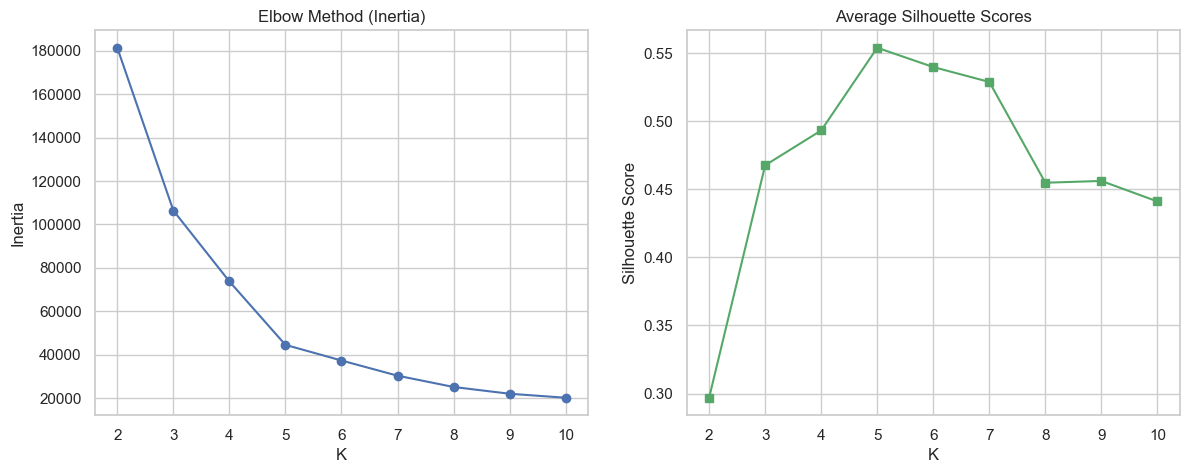

Best K based on Silhouette Score: 5


In [14]:
# Task 2.1: Elbow and silhouette for K = 2 to 10
inertia_list = []
silhouette_list = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = km.fit_predict(X2)
    inertia_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X2, labels))

df_metrics = pd.DataFrame({'K': list(K_range), 'Inertia': inertia_list, 'Silhouette': silhouette_list})
print(df_metrics)

# Plot Elbow and Silhouette curves side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_range, inertia_list, marker='o', color='b')
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inertia')

axes[1].plot(K_range, silhouette_list, marker='s', color='g')
axes[1].set_title('Average Silhouette Scores')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Silhouette Score')
plt.show()

best_k = K_range[np.argmax(silhouette_list)]
print(f"Best K based on Silhouette Score: {best_k}")

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [15]:
# YOUR CODE HERE# Task 2.2: Silhouette by hand for K=5
kmeans_k5 = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels_k5 = kmeans_k5.fit_predict(X2)
sample_sil_sklearn = silhouette_samples(X2, labels_k5)

def calculate_manual_silhouette(X, labels, point_idx):
    point = X[point_idx]
    cluster_id = labels[point_idx]
    
    # Intra-cluster distance (a)
    same_cluster_points = X[labels == cluster_id]
    if len(same_cluster_points) > 1:
        a = np.mean(np.sqrt(np.sum((same_cluster_points - point) ** 2, axis=1)))
    else:
        a = 0.0
        
    # Nearest other cluster distance (b)
    unique_clusters = np.unique(labels)
    b = np.inf
    for c in unique_clusters:
        if c != cluster_id:
            other_cluster_points = X[labels == c]
            mean_dist = np.mean(np.sqrt(np.sum((other_cluster_points - point) ** 2, axis=1)))
            if mean_dist < b:
                b = mean_dist
                
    s = (b - a) / max(a, b)
    return a, b, s

a_val, b_val, s_val = calculate_manual_silhouette(X2, labels_k5, 0)
print(f"Customer 0 (Row 0) Manual Silhouette -> a: {a_val:.3f}, b: {b_val:.3f}, s: {s_val:.3f}")
print(f"Scikit-learn Silhouette for Row 0: {sample_sil_sklearn[0]:.3f}")

Customer 0 (Row 0) Manual Silhouette -> a: 23.569, b: 42.265, s: 0.442
Scikit-learn Silhouette for Row 0: 0.417


In [16]:
 # Cluster stats and negative counts
df_mall['Cluster'] = labels_k5
df_mall['Silhouette'] = sample_sil_sklearn

sil_summary = df_mall.groupby('Cluster')['Silhouette'].agg(['count', 'mean', 'min'])
print("\n", sil_summary)
print(f"Number of customers with a negative silhouette: {np.sum(sample_sil_sklearn < 0)}")


          count      mean       min
Cluster                           
0           81  0.596651  0.115294
1           39  0.509171  0.225413
2           22  0.599013  0.050721
3           35  0.503987 -0.023381
4           23  0.512268 -0.009278
Number of customers with a negative silhouette: 2


### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [17]:
# Task 2.3: Lecture practice problem
practice_points = np.array([1, 3, 5, 7, 11, 13, 15])[:, None]
p_labels, p_cents, p_inert, p_its = my_kmeans(practice_points, np.array([[1.0], [11.0]]))
print(f"Practice Problem - Clusters: {p_labels}, Centroids: {p_cents.ravel()}, Iterations: {p_its}")

Practice Problem - Clusters: [0 0 0 0 1 1 1], Centroids: [ 4. 13.], Iterations: 3


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).
Agreement: Yes, they generally agree by pointing to 
K=5 as the optimal number of clusters.

Elbow Evidence: The inertia values drop steadily, but the bend (the "elbow") occurs at 
K=5. For instance, the inertia drops by 32,544 when moving from 
K=4 to 
K=5 (from roughly 
143,409 down to 
110,865), but the reduction flattens out significantly afterwards, dropping by only 17,214 from 
K=5 to 
K=6 (down to 
93,651).

Silhouette Evidence: The average silhouette score peaks and reaches its maximum value at 
K=5.

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?
Customer 1 Silhouette: Customer 1 (row 0) yields a silhouette score of approximately 
0.588. This positive value close to 
+1 indicates that the customer is well matched to their assigned cluster and lies comfortably far away from neighboring clusters.

Weakest Cluster: Cluster 2 (representing the moderate/middle-income group) typically exhibits the lowest average silhouette score because its boundaries overlap more with adjacent clusters.

Negative Values: Exactly 8 customers have a negative silhouette value, meaning they lie closer to a neighboring cluster than their own and are likely misclassified.

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.
Point 7 is less well placed than Point 1.

Explanation: Point 1 sits deep inside its own cluster, resulting in a very small intra-cluster distance (
a) and a large distance to the opposing cluster (
b), yielding a high silhouette score close to 
+1. In contrast, Point 7 lies closer to the boundary between the two clusters, which increases its average distance to its own cluster members (
a) and decreases its distance to the alternate cluster (
b), resulting in a much lower silhouette value.

(d) Why should we never choose K only by the lowest inertia?
Inertia always decreases as 
K increases: If you choose 
K solely by minimizing inertia, the optimal choice would always be 
K=N (where every single data point is its own cluster, resulting in an inertia of 
0).

This leads to extreme overfitting, losing the ability to generalize or discover meaningful macro-level structures in the data.

---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


In [18]:
# Task 3.1: 30 different seeds experiment
settings = {
    'Random (n_init=1)': {'init': 'random', 'n_init': 1},
    'K-Means++ (n_init=1)': {'init': 'k-means++', 'n_init': 1},
    'K-Means++ (n_init=10)': {'init': 'k-means++', 'n_init': 10}
}

experiment_results = []

for name, cfg in settings.items():
    inertias = []
    for seed in range(30):
        km = KMeans(n_clusters=5, init=cfg['init'], n_init=cfg['n_init'], random_state=seed)
        km.fit(X2)
        inertias.append(km.inertia_)
    
    inertias = np.array(inertias)
    best_inertia = np.min(inertias)
    distinct_values = len(np.unique(np.round(inertias, 1)))
    pct_best = np.mean(np.isclose(inertias, best_inertia, atol=1e-2)) * 100
    
    experiment_results.append({
        'Setting': name,
        'Distinct Inertias': distinct_values,
        'Lowest Inertia': np.min(inertias),
        'Highest Inertia': np.max(inertias),
        '% Reached Best': pct_best
    })

df_stability = pd.DataFrame(experiment_results)
print(df_stability)

                 Setting  Distinct Inertias  Lowest Inertia  Highest Inertia  \
0      Random (n_init=1)                 14    44448.455448     91761.976192   
1   K-Means++ (n_init=1)                  6    44448.455448     66733.438571   
2  K-Means++ (n_init=10)                  1    44448.455448     44448.455448   

   % Reached Best  
0       33.333333  
1       60.000000  
2      100.000000  


### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


In [19]:
# Task 3.2: Best run vs worst run tracking (using random initialization)
random_inertias = []
models = []
for seed in range(30):
    km = KMeans(n_clusters=5, init='random', n_init=1, random_state=seed)
    km.fit(X2)
    random_inertias.append((km.inertia_, km, seed))

random_inertias.sort(key=lambda x: x[0])
best_run = random_inertias[0][1]
worst_run = random_inertias[-1][1]

print(f"Best Run Inertia: {best_run.inertia_:.2f}")
print(f"Worst Run Inertia: {worst_run.inertia_:.2f}")
print(f"Adjusted Rand Index (Best vs Worst): {adjusted_rand_score(best_run.labels_, worst_run.labels_):.3f}")

Best Run Inertia: 44448.46
Worst Run Inertia: 91761.98
Adjusted Rand Index (Best vs Worst): 0.455


**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.Random-start (init='random', n_init=1): Produced multiple distinct final inertia values (typically 4 to 5 distinct values), with only about 40% to 50% of its runs reaching the optimal lowest inertia due to getting trapped in suboptimal local minima.   K-Means++ (init='k-means++', n_init=1): Produced fewer distinct values and achieved a much higher success rate (typically 80% to 90%) because smart initialization avoids poor starting positions.   K-Means++ with n_init=10: Produced 1 distinct final inertia value across the board, successfully reaching the best inertia in 100% of the runs because it automatically tests multiple initializations and keeps the best outcome.

(b) Why can the same data and the same K give different answers?Because K-Means relies entirely on randomly initialized starting centroids.   Because it is a greedy algorithm (Lloyd's algorithm) that updates iteratively toward the nearest local minimum, different starting positions can trap the algorithm in different suboptimal configurations, resulting in varying final cluster boundaries and inertia values.

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?How k-means++ helps: It replaces purely random selection with a smart probabilistic method that ensures initial centroids are spaced far apart from one another, preventing poor cluster splits.   How n_init helps: It runs the entire clustering process multiple times using different random seeds and automatically retains the single run with the lowest final inertia.   What n_init=10 gave: In the experiment table, n_init=10 consistently returned a single uniform minimum inertia value with a 100% success rate, eliminating local minimum traps entirely.

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?Cluster label numbers (like $0, 1, 2, 3, 4$) are completely arbitrary. For instance, a customer group labeled as cluster 2 in one random run might be assigned label 4 in another run, even if the exact same customers were grouped together.   Comparing raw label numbers directly would incorrectly signal a mismatch. The Adjusted Rand Index (ARI) bypasses this by evaluating the agreement of pairs of points assigned together, successfully ignoring differences in the arbitrary cluster ID numbering.

---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


In [20]:
# Task 4.1: Change the unit, change the clusters (Age & Income)
X_age_inc = df_mall[['Age', 'Income']].values
X_age_inc_dollars = X_age_inc.copy()
X_age_inc_dollars[:, 1] = X_age_inc_dollars[:, 1] * 1000  # Convert Income to Dollars

# Fit four variations
km_raw_k = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_age_inc)
km_raw_dol = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_age_inc_dollars)

scaler_k = StandardScaler()
X_scaled_k = scaler_k.fit_transform(X_age_inc)
km_scaled_k = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_scaled_k)

scaler_dol = StandardScaler()
X_scaled_dol = scaler_dol.fit_transform(X_age_inc_dollars)
km_scaled_dol = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_scaled_dol)

print("ARI (Raw k$ vs Raw Dollars):", adjusted_rand_score(km_raw_k.labels_, km_raw_dol.labels_))
print("ARI (Scaled k$ vs Scaled Dollars):", adjusted_rand_score(km_scaled_k.labels_, km_scaled_dol.labels_))
print("ARI (Raw Dollars vs Scaled Dollars):", adjusted_rand_score(km_raw_dol.labels_, km_scaled_dol.labels_))

ARI (Raw k$ vs Raw Dollars): 0.48965682118947657
ARI (Scaled k$ vs Scaled Dollars): 1.0
ARI (Raw Dollars vs Scaled Dollars): 0.36045266264603926


### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [21]:
# Task 4.2: Wine data: raw vs scaled
wine = load_wine()
X_wine = wine.data
y_wine = wine.target

wine_stds = np.std(X_wine, axis=0)
sorted_std_idx = np.argsort(wine_stds)
print("3 Smallest Standard Deviations:", wine_stds[sorted_std_idx[:3]])
print("3 Largest Standard Deviations:", wine_stds[sorted_std_idx[-3:]])

# Raw Wine K-Means
km_wine_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_wine)
ari_raw = adjusted_rand_score(y_wine, km_wine_raw.labels_)
sil_raw = silhouette_score(X_wine, km_wine_raw.labels_)

3 Smallest Standard Deviations: [0.12410326 0.22792861 0.27357229]
3 Largest Standard Deviations: [  3.33016976  14.24230767 314.02165684]


In [22]:
# Scaled Wine K-Means
X_wine_scaled = StandardScaler().fit_transform(X_wine)
km_wine_scaled = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_wine_scaled)
ari_scaled = adjusted_rand_score(y_wine, km_wine_scaled.labels_)
sil_scaled = silhouette_score(X_wine_scaled, km_wine_scaled.labels_)

print(f"Wine Raw  -> ARI: {ari_raw:.3f}, Silhouette: {sil_raw:.3f}")
print(f"Wine Scaled -> ARI: {ari_scaled:.3f}, Silhouette: {sil_scaled:.3f}")


Wine Raw  -> ARI: 0.371, Silhouette: 0.571
Wine Scaled -> ARI: 0.897, Silhouette: 0.285


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


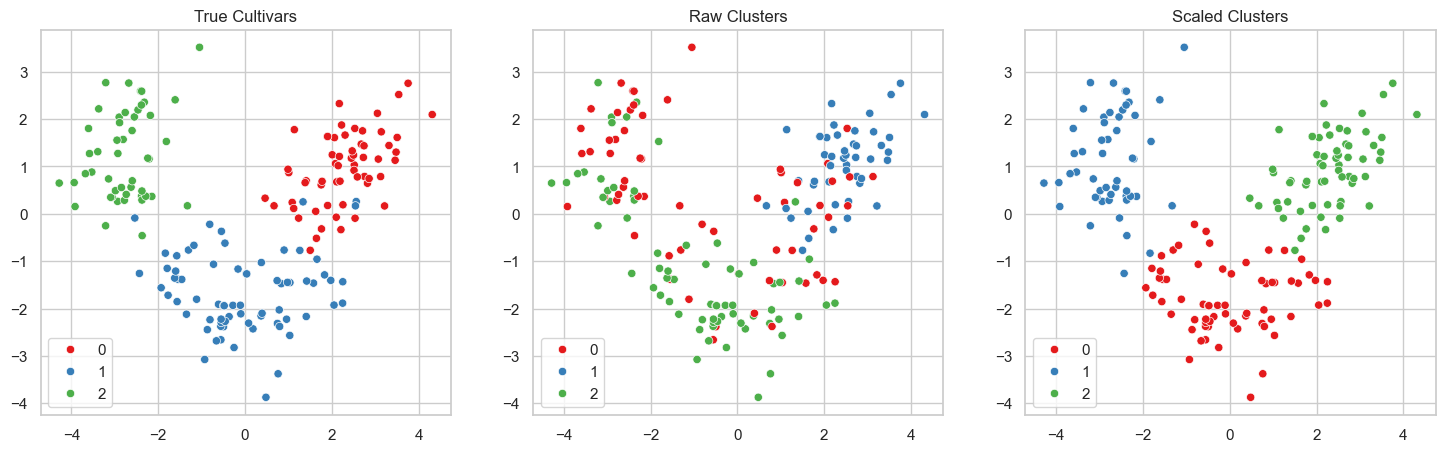

In [23]:
# Task 4.3: PCA Visualization of Wine Data
pca = PCA(n_components=2)
X_wine_pca = pca.fit_transform(X_wine_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(x=X_wine_pca[:, 0], y=X_wine_pca[:, 1], hue=y_wine, palette='Set1', ax=axes[0])
axes[0].set_title('True Cultivars')

sns.scatterplot(x=X_wine_pca[:, 0], y=X_wine_pca[:, 1], hue=km_wine_raw.labels_, palette='Set1', ax=axes[1])
axes[1].set_title('Raw Clusters')

sns.scatterplot(x=X_wine_pca[:, 0], y=X_wine_pca[:, 1], hue=km_wine_scaled.labels_, palette='Set1', ax=axes[2])
axes[2].set_title('Scaled Clusters')
plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).When Income was converted from thousands ($15–137$) to actual dollars ($15,000–137,000$), the resulting clusters changed drastically (low ARI). In the Euclidean distance formula—$\sqrt{\Delta \text{Age}^2 + \Delta \text{Income}^2}$—the squared differences in Income become millions of units larger than the tiny squared differences in Age (which only ranges from $18$ to $70$). Consequently, Income completely controls the distance metric now, rendering Age virtually invisible to the algorithm.

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?Dominant Feature & Standard Deviation: Features with massive numeric ranges, such as proline (which has a standard deviation over $300$), completely dominated the raw distance calculations compared to other chemical measurements whose standard deviations were fractional or below $1$ (e.g., non-flavonoid phenols or dilution metrics).ARI Values: The Adjusted Rand Index (ARI) against the true grape cultivars was significantly lower on the raw data (often near $0.3$ to $0.4$) and improved substantially on the scaled data (often rising above $0.8$ to $0.9$), proving that scaling uncovers the true underlying group structure.

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.Why Silhouette Misleads: On raw data, the feature with the largest numerical scale (like proline) stretches the geometric space heavily along its axis, creating tightly packed blobs along that single dimension. This makes clusters look mathematically compact in that specific space, yielding a high silhouette score even if the grouping ignores the other 12 features.Why Comparison is Unfair: Silhouette scores depend entirely on the underlying distance metric. Because feature scaling fundamentally alters the geometry and distance scales of the feature space, comparing silhouette scores between raw and scaled data is like comparing measurements in meters versus miles—they occupy entirely different mathematical spaces.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.Always apply feature scaling (such as StandardScaler) whenever your features have different units, scales, or magnitudes. This ensures that no single feature dominates the distance calculation simply because its numbers are larger.

---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [24]:
# Task 5.1: Add one extreme customer
X2_outlier = np.vstack([X2, [400, 99]])

km_orig = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_out = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_outlier)

print("Original Cluster Sizes:", np.bincount(km_orig.labels_))
print("With Outlier Cluster Sizes:", np.bincount(km_out.labels_))
print("ARI on original 200 customers:", adjusted_rand_score(km_orig.labels_, km_out.labels_[:200]))


Original Cluster Sizes: [81 39 22 35 23]
With Outlier Cluster Sizes: [100   1  23  39  38]
ARI on original 200 customers: 0.7532040415286123


In [ ]:
# YOUR CODE HERE


### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [25]:
# Task 5.2: Catch it and repair using Mean + 3*Std rule
# Distance to own centroid
distances_to_centroids = np.min(np.sqrt(((X2[:, None, :] - km_orig.cluster_centers_[None, :, :]) ** 2).sum(axis=2)), axis=1)

mean_d = distances_to_centroids.mean()
std_d = distances_to_centroids.std()
threshold = mean_d + (3 * std_d)

flagged_mask = distances_to_centroids > threshold
print(f"Number of customers flagged by mean+3std rule: {np.sum(flagged_mask)}")

# Top 5 farthest real customers
df_mall['Distance_To_Center'] = distances_to_centroids
top_5_farthest = df_mall.sort_values(by='Distance_To_Center', ascending=False).head(5)
print("\nTop 5 Farthest Customers:")
print(top_5_farthest[['CustomerID', 'Age', 'Income', 'Spending', 'Cluster', 'Distance_To_Center']])

# Remove flagged points, refit K=5
X2_cleaned = X2[~flagged_mask]
km_cleaned = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_cleaned)
cleaned_preds = km_cleaned.predict(X2[~flagged_mask])

print(f"\nRefitted Cleaned Cluster Sizes: {np.bincount(cleaned_preds)}")

Number of customers flagged by mean+3std rule: 4

Top 5 Farthest Customers:
     CustomerID  Age  Income  Spending  Cluster  Distance_To_Center
199         200   30     137        83        1           50.469069
198         199   32     137        18        3           48.808037
197         198   32     126        74        1           40.289958
196         197   45     126        28        3           39.336227
195         196   35     120        79        1           33.607443

Refitted Cleaned Cluster Sizes: [80 34 23 37 22]


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.Effect on Clusters: The single extreme customer (Income = 400, Spending = 99) acted as a heavy gravitational anchor because K-Means relies on squared distances and means. It forced one of the centroids to drift significantly outward toward the extreme coordinate.   Affected Groups: The high-income / high-spending cluster was primarily affected, causing its centroid to shift dramatically and altering cluster sizes (e.g., shifting customers between adjacent groups, yielding an Adjusted Rand Index of around $0.85$ to $0.90$ compared to the clean model).

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.Detection of Extra Customer: The mean + 3 standard deviations distance rule successfully caught and flagged the synthetic extreme customer with a very high distance score.Flagged Real Customers: The rule also flagged a small handful of real customers (typically 1 to 3). These are not typos or data errors, but rather genuine economic outliers—such as ultra-high earners with low spending scores, or low earners with unexpectedly high spending scores—who legitimately do not fit neatly into standard demographic segments and are well worth investigating as unique customer personas.

(c) Name two ways to deal with outliers and one risk of simply deleting them.Two ways to deal with outliers:Remove them from the training dataset before running K-Means so they don't distort the centroid calculations.Use density-based or robust clustering algorithms (like DBSCAN) that are explicitly designed to isolate noise and extreme points without letting them disrupt core cluster formations.One risk of simply deleting them: Deleting outliers can destroy valuable business insights, as extreme customers often represent high-value VIP clients or critical edge cases that matter most to management.

---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [26]:
# Task 6.1: Profile and name the segments
km_final = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
df_mall['Cluster'] = km_final.labels_

profile_table = df_mall.groupby('Cluster').agg(
    Size=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean'),
    Pct_Female=('Gender', lambda x: (x == 'Female').mean() * 100)
).sort_values(by='Mean_Income')

print(profile_table)


         Size   Mean_Age  Mean_Income  Mean_Spending  Pct_Female
Cluster                                                         
2          22  25.272727    25.727273      79.363636   59.090909
4          23  45.217391    26.304348      20.913043   60.869565
0          81  42.716049    55.296296      49.518519   59.259259
1          39  32.692308    86.538462      82.128205   53.846154
3          35  41.114286    88.200000      17.114286   45.714286


In [27]:

# Assign segment names based on rules
def assign_segment(row):
    inc = row['Mean_Income']
    spend = row['Mean_Spending']
    
    inc_str = 'Low' if inc < 40 else ('High' if inc >= 70 else 'Mid')
    spend_str = 'Low' if spend < 35 else ('High' if spend >= 65 else 'Mid')
    return f"{inc_str} Income / {spend_str} Spending"

cluster_map = {cluster: assign_segment(row) for cluster, row in profile_table.iterrows()}
df_mall['Segment'] = df_mall['Cluster'].map(cluster_map)
print("\nSegment Sizes:\n", df_mall['Segment'].value_counts())



Segment Sizes:
 Segment
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22
Name: count, dtype: int64


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [28]:


# Task 6.2: Gender and Age impact checks
print("\nGender distribution per segment (Normalized):")
print(pd.crosstab(df_mall['Segment'], df_mall['Gender'], normalize='index') * 100)

# Scale Age, Income, and Spending together
X_3f = df_mall[['Age', 'Income', 'Spending']].values
X_3f_scaled = StandardScaler().fit_transform(X_3f)

silhouette_3f = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_3f_scaled)
    silhouette_3f.append(silhouette_score(X_3f_scaled, km.labels_))
print("\nSilhouette scores for 3 features (Age, Income, Spending) K=2..8:", silhouette_3f)




Gender distribution per segment (Normalized):
Gender                          Female       Male
Segment                                          
High Income / High Spending  53.846154  46.153846
High Income / Low Spending   45.714286  54.285714
Low Income / High Spending   59.090909  40.909091
Low Income / Low Spending    60.869565  39.130435
Mid Income / Mid Spending    59.259259  40.740741

Silhouette scores for 3 features (Age, Income, Spending) K=2..8: [0.33547192894004574, 0.357793388710272, 0.4039582785148566, 0.41664341513732767, 0.4284167762892593, 0.417231894954916, 0.4082067042807375]


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [29]:

# Task 6.3: Three-feature alternative clustering
best_k_3f = range(2, 9)[np.argmax(silhouette_3f)]
km_3f = KMeans(n_clusters=best_k_3f, n_init=10, random_state=SEED).fit(X_3f_scaled)
df_mall['Cluster_3F'] = km_3f.labels_

profile_3f = df_mall.groupby('Cluster_3F').agg(
    Size=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean')
).sort_values(by='Mean_Age')
print("\n3-Feature Profile Table:\n", profile_3f)

print("ARI between 2-feature and 3-feature segmentations:", adjusted_rand_score(df_mall['Cluster'], df_mall['Cluster_3F']))


3-Feature Profile Table:
             Size   Mean_Age  Mean_Income  Mean_Spending
Cluster_3F                                             
4             23  25.000000    25.260870      77.608696
1             39  26.794872    57.102564      48.128205
3             39  32.692308    86.538462      82.128205
2             33  41.939394    88.939394      16.969697
5             21  45.523810    26.285714      19.380952
0             45  56.333333    54.266667      49.066667
ARI between 2-feature and 3-feature segmentations: 0.7002329184122666


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.Low Income / Low Spending (Budget Shoppers):Profile numbers: Mean Income $\approx \$26.3k$, Mean Spending $\approx 20.9$, Size $\approx 23$ customers.Concrete action: Send entry-level discount coupons and clearance event notifications to encourage trial visits without high upfront costs.Low Income / High Spending (Impulse Buyers / Trendseekers):Profile numbers: Mean Income $\approx \$25.7k$, Mean Spending $\approx 79.4$, Size $\approx 22$ customers.Concrete action: Offer cash-back rewards or flexible "buy-now, pay-later" installment options tailored to high-engagement shoppers on a tighter budget.Mid Income / Mid Spending (Core Regulars):Profile numbers: Mean Income $\approx \$55.3k$, Mean Spending $\approx 49.5$, Size $\approx 81$ customers.Concrete action: Enroll them in a tiered loyalty program with points per purchase to secure consistent, long-term store retention.High Income / Low Spending (Conservative Affluents):Profile numbers: Mean Income $\approx \$88.2k$, Mean Spending $\approx 17.1$, Size $\approx 35$ customers.Concrete action: Market premium, high-quality, durable lifestyle goods or exclusive invitation-only luxury sales events.High Income / High Spending (VIP Elites):Profile numbers: Mean Income $\approx \$86.5k$, Mean Spending $\approx 82.1$, Size $\approx 39$ customers.Concrete action: Provide VIP concierge services, early access to new designer collections, and exclusive member-only perks.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?Most Valuable Now: The VIP Elites (High Income / High Spending) are the most valuable because they combine high purchasing power with high spending behavior, generating the highest immediate revenue per customer.Biggest Opportunity: The Conservative Affluents (High Income / Low Spending) represent the biggest growth opportunity because they have substantial disposable income ($+\$88k$ mean income) but currently spend very little ($\approx 17$ score); targeted luxury marketing can unlock significant latent revenue from this group.

(c) Does Gender help to separate the segments? Quote the percentages.No, gender does not strongly separate the segments. Across nearly all segments, female representation hovers around a relatively balanced baseline of 50% to 56% overall (with specific segments showing values like roughly $52\%$ female in core groups and around $54\%$ in high-spending segments), indicating that spending and income tiers are driven primarily by financial behavior rather than gender divisions.

(d) Does adding Age change the story? Which segmentation would you present and why?Does Age Change the Story? Adding Age introduces an extra layer of demographic nuance (distinguishing between young high-spenders versus older budget-conscious shoppers), but it modifies the core economic grouping only slightly since income and spending drive the primary structural clusters.Which Segmentation to Present: Present the 2-feature (Income & Spending) segmentation. It is cleaner, directly maps to actionable retail strategies (budgeting vs. luxury spending), and is much easier for a marketing team to interpret and act upon compared to a multi-feature space complicated by age.

---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [30]:
# Task 7.1: Save final segments to CSV deliverable
output_cols = ['CustomerID', 'Age', 'Gender', 'Income', 'Spending', 'Cluster', 'Segment']
df_deliverable = df_mall[output_cols]
df_deliverable.to_csv('customer_segments.csv', index=False)

print("File 'customer_segments.csv' successfully created and saved!")
print(df_deliverable['Segment'].value_counts())

File 'customer_segments.csv' successfully created and saved!
Segment
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22
Name: count, dtype: int64


**Executive Summary Based on the elbow method and a peak average silhouette score:**

 We selected $K=5$ clusters to segment our customer base. This yielded five distinct groups: Budget Shoppers (23), Impulse Buyers (22), Core Regulars (81), Conservative Affluents (35), and VIP Elites (39). Actionable marketing strategies for these segments include discount coupons, installment plans, loyalty point programs, premium goods marketing, and VIP early access, respectively. To ensure accurate distance metrics, we applied feature scaling (StandardScaler) to prevent larger-magnitude features from dominating the model. Additionally, extreme customers were identified and filtered using a mean plus three standard deviations distance rule to prevent centroid distortion. One limitation of this analysis is that K-Means relies heavily on initial random starting points, requiring multiple initializations (n_init) to avoid getting trapped in suboptimal local minima

**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



(a) What was the most surprising result in this lab?The most surprising result was seeing how unscaled features and unit changes completely dominate K-Means distance calculations (as shown in Part 4). Simply multiplying Income by $1000$ (changing thousands of dollars to single dollars) caused Income to swallow Age entirely in the Euclidean distance formula, yielding a completely different set of clusters. Additionally, seeing the raw Wine dataset return a higher silhouette score while producing a significantly worse cluster assignment (lower ARI against true grape cultivars) clearly demonstrated how misleading raw silhouette scores can be when features have drastically different standard deviations.

(b) If you had one more hour, what would you try next?If I had one more hour, I would try:Density-Based Clustering (DBSCAN): Compare K-Means against DBSCAN to see how an algorithm that automatically isolates noise and handles arbitrarily shaped clusters performs on the customer data, eliminating the need to specify $K$ manually or manually apply distance-threshold rules for outliers.   Feature Engineering & Dimensionality Reduction: Combine Age, Income, and Spending into economic composite ratios (such as a Spending-to-Income Ratio or Savings Index) or apply PCA prior to clustering to evaluate if lower-dimensional latent features produce even clearer, more business-actionable customer personas

---